In [ ]:
sentence = ['The', 'cat', 'sat', 'on', 'the', 'mat']

attention_scores = {
	'The' : 0.1,
	'cat' : 1.0,
	'sat' : 0.8,
	'on' : 0.3,
	'the' : 0.1,
	'mat' : 0.6
}

In [ ]:
word_vectors = {
	'The' : [0.1, 0.2, 0.3],
	'cat' : [0.5, 0.8, 0.2],
	'sat' : [0.7, 0.1, 0.9],
	'on' : [0.2, 0.6, 0.3],
	'the' : [0.1, 0.2, 0.3],    # 대소문자 상관없이 같은 단어면 벡터가 같아야함
	'mat' : [0.8, 0.3, 0.5] 
}

new_vector = []

for dim in range(3):
	weighted_sum = (
		0.1 * word_vectors['The'][dim]+
		1.0 * word_vectors['cat'][dim]+
		0.8 * word_vectors['sat'][dim]+
		0.3 * word_vectors['on'][dim]+
		0.1 * word_vectors['the'][dim]+
		0.6 * word_vectors['mat'][dim]
	)
	new_vector.append(weighted_sum)

print(word_vectors['cat'])
print(new_vector)


[0.5, 0.8, 0.2]
[1.6199999999999999, 1.28, 1.37]


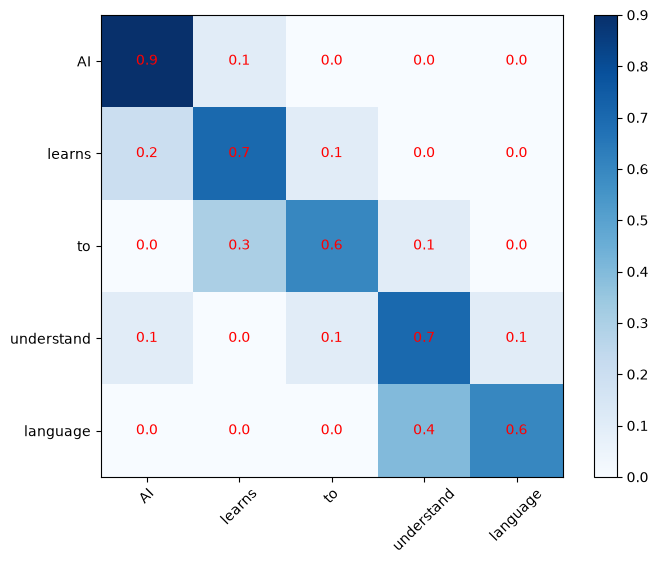

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

words = ['AI', 'learns', 'to', 'understand', 'language']

attention_matrix = np.array([
	[0.9, 0.1, 0.0, 0.0, 0.0],
	[0.2, 0.7, 0.1, 0.0, 0.0],
	[0.0, 0.3, 0.6, 0.1, 0.0],
	[0.1, 0.0, 0.1, 0.7, 0.1],
	[0.0, 0.0, 0.0, 0.4, 0.6]
])

plt.figure(figsize = (8, 6))
plt.imshow(attention_matrix, cmap  = 'Blues')
plt.xticks(range(len(words)), words, rotation = 45)
plt.yticks(range(len(words)), words)
plt.colorbar()

for i in range(len(words)):
	for j in range(len(words)):
		plt.text(j, i, f'{attention_matrix[i, j]:.1f}',
				 ha = 'center', va = 'center', color = 'red')

plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
class SelfAttentionExplainer:
	def __init__(self, d_model = 512):
		self.d_model = d_model
	def step_by_step_attention(self, sentence):
		words = sentence.split()
		vocab_size = len(words)
		embeddings = torch.randn(vocab_size, self.d_model)
		for i, word in enumerate(words):
			print(word, embeddings[i][:5].tolist())

		W_q = torch.randn(self.d_model, self.d_model)
		W_k = torch.randn(self.d_model, self.d_model)
		W_v = torch.randn(self.d_model, self.d_model)

		Q = embeddings @ W_q
		K = embeddings @ W_k
		V = embeddings @ W_v

		print(Q.shape)
		print(K.shape)
		print(V.shape)

		scores = Q @ K.T / np.sqrt(self.d_model)
		print(scores.shape)

		attention_weights = F.softmax(scores, dim = 1)

		plt.figure(figsize = (10, 8))
		plt.imshow(attention_weights.detach().numpy(), cmap = 'Blues')
		plt.xticks(range(len(words)), words, rotation = 45)
		plt.yticks(range(len(words)), words)
		plt.colorbar()

		for i in range(len(words)):
			for j in range(len(words)):
				plt.text(j, i, f'{attention_weights[i, j]:.2f}', ha = 'center', va = 'center',
			 color = 'red' if attention_weights[i, j] > 0.3 else 'black')
		plt.tight_layout()
		plt.show()

		output = attention_weights @ V
		print(output.shape)

		for i, word in enumerate(words):
			top_attention = torch.argmax(attention_weights[i])
			top_word = words[top_attention]
			top_score = attention_weights[i, top_attention].item()
		return output, attention_weights


In [ ]:
def run_attention_demo():
	explainer = SelfAttentionExplainer()
	sentences = [
		'The cat sat on the mat',
		'AI learns to understand language',
		'Transformer models revolutionized NLP'
	]

	for sentence in sentences:
		output, weights = explainer.step_by_step_attention(sentence)
		

In [12]:
class PracticalAttentionExample:
	def __init__(self):
		self.multihead_attn = nn.MultiheadAttention(
			embed_dim = 512,
			num_heads = 8,
			batch_first = True
		)
	def text_classification_with_attention(self):
		batch_size, seq_len, embed_dim = 2, 10, 512
		text_embeddings = torch.randn(batch_size, seq_len, embed_dim)
		attn_output, attn_weights = self.multihead_attn(
			text_embeddings, text_embeddings, text_embeddings)
		print(text_embeddings.shape)
		print(attn_output.shape)
		print(attn_weights.shape)

		classifier = nn.Sequential(
			   nn.Linear(embed_dim, 256),
			   nn.ReLU(),
			   nn.Dropout(0.1),
			   nn.Linear(256, 3)
		)
		pooled = attn_output.mean(dim = 1)
		predictions = classifier(pooled)
		print(predictions.shape)
		return predictions

The [-0.9261770248413086, 0.5593105554580688, -1.2824746370315552, -0.9948548674583435, 0.3642307221889496]
cat [-0.8729749917984009, -0.7273480892181396, 0.005930724088102579, 0.8174668550491333, 0.9398598670959473]
sat [-0.1350012719631195, -1.1104689836502075, -0.4582895040512085, -0.12688705325126648, 0.6683378219604492]
on [-0.7822886109352112, 1.76712965965271, 0.3529333770275116, -0.07990790158510208, -0.8851690888404846]
the [-1.5824302434921265, -0.3066572844982147, -1.240916132926941, -0.13633349537849426, 0.10222595930099487]
mat [-0.6515271663665771, -1.7406516075134277, -0.925783634185791, 0.9169167280197144, 3.097799777984619]
torch.Size([6, 512])
torch.Size([6, 512])
torch.Size([6, 512])
torch.Size([6, 6])


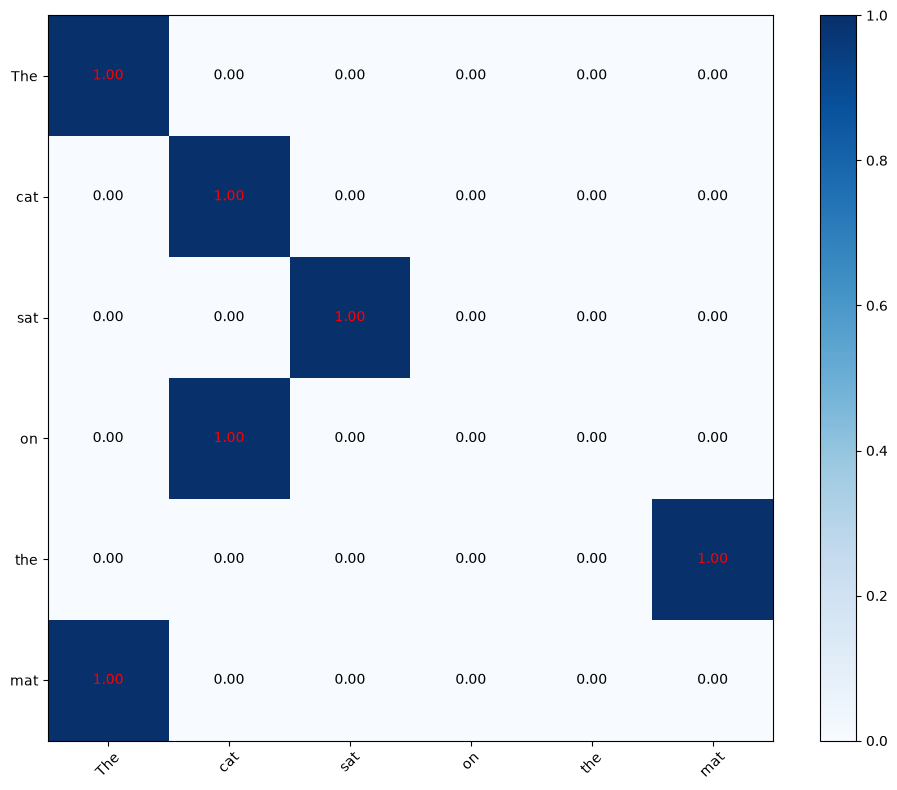

torch.Size([6, 512])
AI [0.21864226460456848, 0.8265789151191711, -1.159731388092041, 0.6306421756744385, -0.5489528179168701]
learns [-0.28762173652648926, -1.3084776401519775, -1.2637522220611572, 0.9769325852394104, 2.0691661834716797]
to [0.35571399331092834, 0.05353834107518196, 0.4770567715167999, -0.5145100355148315, -0.5833335518836975]
understand [-0.5605655312538147, -0.6325363516807556, -0.49457958340644836, -0.8922663927078247, -0.17216120660305023]
language [1.8612695932388306, 1.4619816541671753, -0.2802151143550873, -1.5026977062225342, -0.551435112953186]
torch.Size([5, 512])
torch.Size([5, 512])
torch.Size([5, 512])
torch.Size([5, 5])


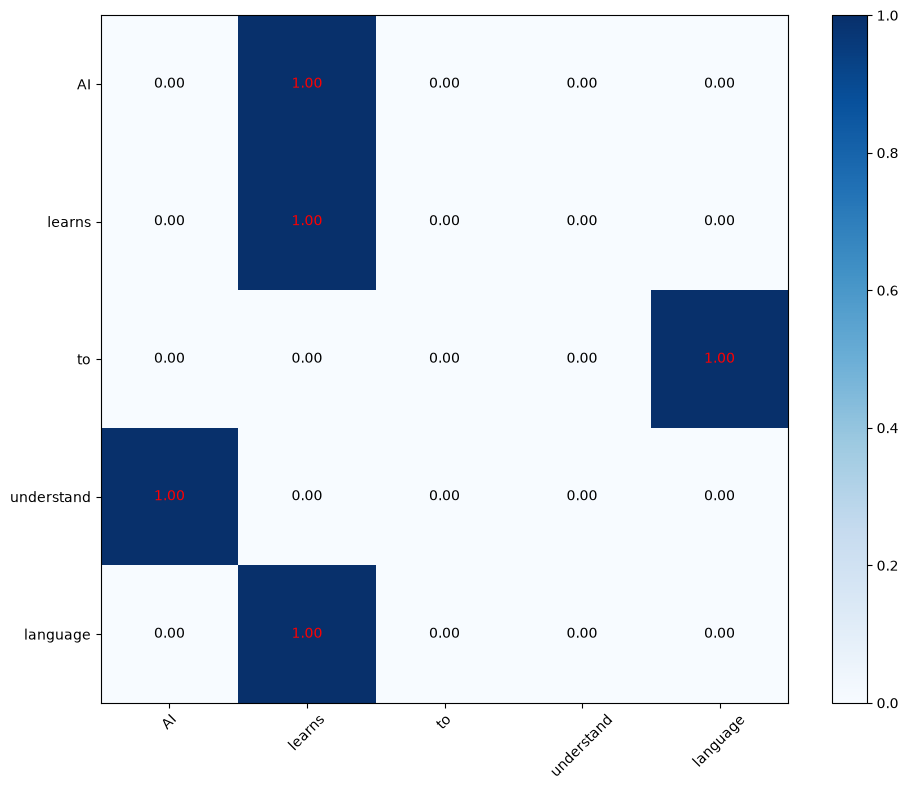

torch.Size([5, 512])
Transformer [-0.43110355734825134, 0.41555631160736084, -1.552446961402893, -0.8224453926086426, 0.133845716714859]
models [-1.767147183418274, -0.5055884122848511, 0.9440641403198242, 0.03765704855322838, -0.07896887511014938]
revolutionized [-0.6357036232948303, 0.9865823984146118, 0.3527630567550659, -1.5733232498168945, -0.1857624500989914]
NLP [-0.9604812264442444, -0.7111973166465759, 1.7559082508087158, -1.1302754878997803, -0.6321583986282349]
torch.Size([4, 512])
torch.Size([4, 512])
torch.Size([4, 512])
torch.Size([4, 4])


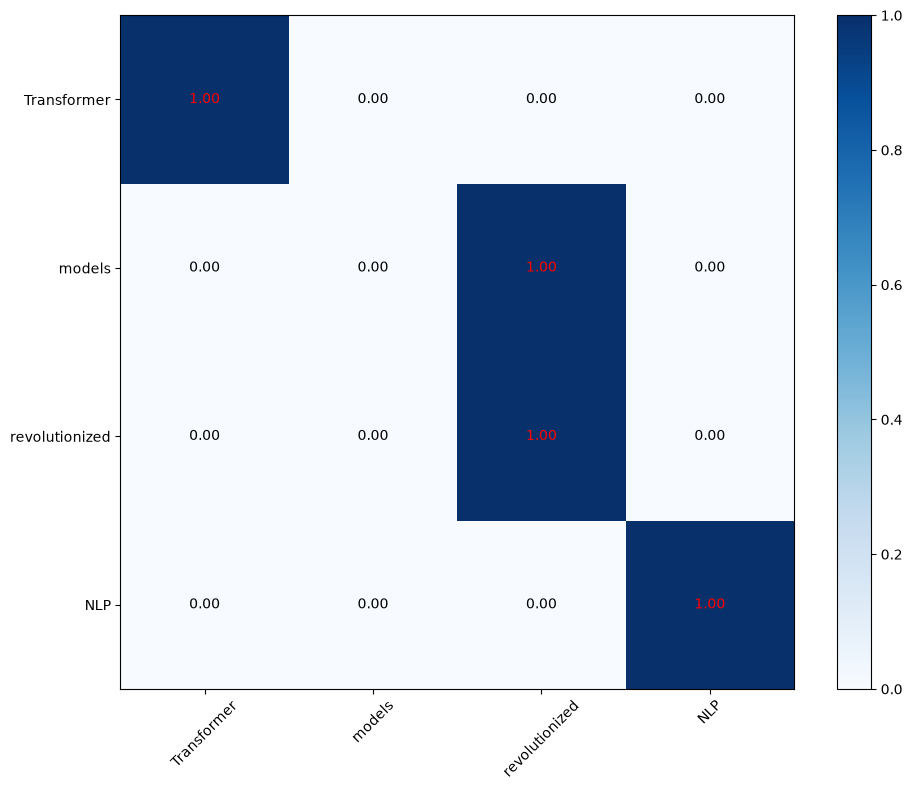

torch.Size([4, 512])
torch.Size([2, 10, 512])
torch.Size([2, 10, 512])
torch.Size([2, 10, 10])
torch.Size([2, 3])


tensor([[ 0.0156,  0.0009,  0.0186],
        [ 0.0019, -0.0131, -0.0380]], grad_fn=<AddmmBackward0>)

In [13]:
run_attention_demo()

practical = PracticalAttentionExample()
practical.text_classification_with_attention()


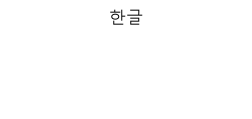

In [15]:
import matplotlib.pyplot as plt
# 한글 글자체 가져오기
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(3, 1))
plt.title('한글')
plt.axis('off')
plt.show()

In [23]:
from transformers import BertTokenizer, BertForSequenceClassification
import torch

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels = 2)

sentence = 'I am freaking want to go home'
inputs = tokenizer(sentence,
                   return_tensors = 'pt',
                   truncation = True,
                   padding = True)

outputs = model(**inputs)
logits = outputs.logits
predicted_class = torch.argmax(logits, dim = 1)
print(predicted_class.item())

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


0


In [27]:
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image 

resnet18 = models.resnet18(pretrained = True)
num_ftrs = resnet18.fc.in_features
resnet18.fc = nn.Linear(num_ftrs, 10)

resnet18.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
	transforms.Normalize(mean = [0.485, 0.456, 0.406],
                      std = [0.229, 0.224, 0.225])    
])

img = Image.open('example.jpg').convert('RGB')
img_t = transform(img)
img_t = img_t.unsqueeze(0)
outputs = resnet18(img_t)
_, predicted = torch.max(outputs, 1)
print(predicted.item())

7


In [26]:
from transformers import BertTokenizer, BertForSequenceClassification
import torch
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

sentences = ['I love this movie',
             'I hate this movie',
             'It was okay',
             'Fantastic film',
             'Terrible experience']
labels = torch.tensor([1, 0, 1, 1, 0])

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased') # uncased : 대소문자 구분 안함
encoded_inputs = tokenizer(sentences, padding = True, truncation = True, return_tensors = 'pt')
dataset = TensorDataset(encoded_inputs['input_ids'], labels)
train_loader = DataLoader(dataset, batch_size = 2, shuffle = True)

model_fe = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels = 2)

for param in model_fe.bert.parameters():
    param.requires_grad = False
optimizer_fe = optim.Adam(model_fe.parameters(), lr = 2e-5)

model_ft = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels = 2)

optimizer_ft = optim.Adam(model_ft.parameters(), lr = 2e-5)


def train_model(model, optimizer, epochs = 3):
    model.train()
    for epoch in range(epochs):
        for input_ids, label in train_loader:
            optimizer.zero_grad()
            outputs = model(input_ids = input_ids, labels = label)
            loss = outputs.loss
            loss.backward()
            optimizer.step()

train_model(model_fe, optimizer_fe)
train_model(model_ft, optimizer_ft)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
